# Práctica 2: Manuel Alejandro Serrano Macias
# The Bag of Words

In [1]:
def get_texts_from_file(path_corpus, path_truth):
  tr_txt = [] # aqui van los tuits
  tr_y = []   # aqui van las etiquetas de las psicologas

  with open(path_corpus, "r", encoding="utf-8") as f_corpus, open (path_truth, "r", encoding="utf-8") as f_truth:

    for twitt in f_corpus:
      tr_txt += [twitt]
    
    for label in f_truth:
      tr_y += [label]

  return tr_txt, tr_y

In [2]:
tr_txt, tr_y = get_texts_from_file("./mex20_train.txt","./mex20_train_labels.txt")

## Ver datos

In [3]:
import matplotlib.pyplot as plt
from collections import Counter

%matplotlib inline

print(Counter(tr_y))

Counter({'0\n': 3759, '1\n': 1519})


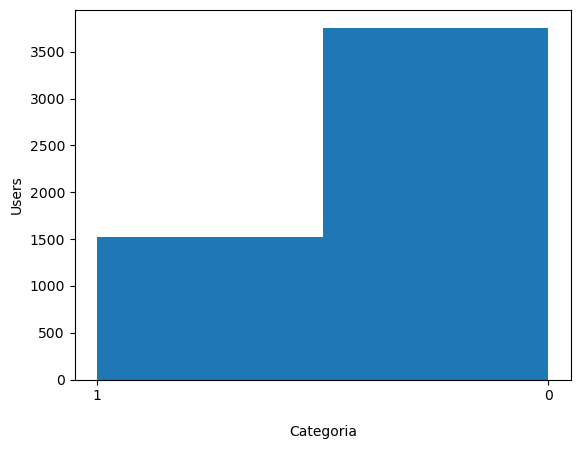

In [4]:
plt.hist(tr_y, bins=len(set(tr_y)))

plt.ylabel("Users")
plt.xlabel("Categoria")

plt.show()

## Token

In [5]:
tr_txt[61]

'🤣🤣🤣 mi vida, eres la mejor! Dí lo q digas y a la verga los haters heteropatriarcanormados! Block y be happy! 😘\n'

In [6]:
tr_txt[61].split()

['🤣🤣🤣',
 'mi',
 'vida,',
 'eres',
 'la',
 'mejor!',
 'Dí',
 'lo',
 'q',
 'digas',
 'y',
 'a',
 'la',
 'verga',
 'los',
 'haters',
 'heteropatriarcanormados!',
 'Block',
 'y',
 'be',
 'happy!',
 '😘']

In [7]:
import nltk

In [8]:
from nltk.tokenize import TweetTokenizer
tokenizer = TweetTokenizer()

In [9]:
tokenizer.tokenize(tr_txt[61] + "www.youtube.com" + "ljksadfasklfa")

['🤣',
 '🤣',
 '🤣',
 'mi',
 'vida',
 ',',
 'eres',
 'la',
 'mejor',
 '!',
 'Dí',
 'lo',
 'q',
 'digas',
 'y',
 'a',
 'la',
 'verga',
 'los',
 'haters',
 'heteropatriarcanormados',
 '!',
 'Block',
 'y',
 'be',
 'happy',
 '!',
 '😘',
 'www.youtube',
 '.',
 'comljksadfasklfa']

In [10]:
import nltk

corpus_palabras = []
for doc in tr_txt:
  corpus_palabras += tokenizer.tokenize(doc.lower())

In [11]:
len(corpus_palabras)

97473

In [12]:
len(set(corpus_palabras))

13117

In [13]:
fdist = nltk.FreqDist(corpus_palabras)

In [14]:
type(fdist)

nltk.probability.FreqDist

In [15]:
fdist

FreqDist({'que': 3111, 'de': 3094, ',': 3016, '.': 2604, 'la': 2269, 'a': 2205, 'y': 2098, 'no': 1819, 'me': 1475, '!': 1435, ...})

In [16]:
tokens=nltk.word_tokenize(tr_txt[61])
print(tokens)

['🤣🤣🤣', 'mi', 'vida', ',', 'eres', 'la', 'mejor', '!', 'Dí', 'lo', 'q', 'digas', 'y', 'a', 'la', 'verga', 'los', 'haters', 'heteropatriarcanormados', '!', 'Block', 'y', 'be', 'happy', '!', '😘']


In [17]:
def sortFreqDist(freqdict): 
  aux = [(freqdict[key], key) for key in freqdict]
  aux.sort()
  aux.reverse()
  return aux # se convierte en el diccionario

In [18]:
V = sortFreqDist(fdist)

In [19]:
V = V[:5000]

In [20]:
# V # [(3111, 'que'), (3094, 'de')]

In [21]:
dict_indices = dict()

count = 0
for frecuencia, word in V:
  dict_indices[word] = count
  count += 1

In [22]:
dict_indices # {'que': 0, 'de': 1, ',': 2, ..}

{'que': 0,
 'de': 1,
 ',': 2,
 '.': 3,
 'la': 4,
 'a': 5,
 'y': 6,
 'no': 7,
 'me': 8,
 '!': 9,
 '@usuario': 10,
 'el': 11,
 'en': 12,
 'se': 13,
 'es': 14,
 'verga': 15,
 'madre': 16,
 'los': 17,
 'con': 18,
 'por': 19,
 '?': 20,
 'las': 21,
 'mi': 22,
 'un': 23,
 'te': 24,
 'ya': 25,
 'si': 26,
 'putos': 27,
 'lo': 28,
 '"': 29,
 'putas': 30,
 'una': 31,
 'para': 32,
 'como': 33,
 '...': 34,
 'pero': 35,
 'su': 36,
 '😂': 37,
 'tu': 38,
 'loca': 39,
 'le': 40,
 'más': 41,
 'gorda': 42,
 'yo': 43,
 'del': 44,
 'al': 45,
 'cuando': 46,
 'o': 47,
 'bien': 48,
 'son': 49,
 'estoy': 50,
 '¿': 51,
 'qué': 52,
 'porque': 53,
 'feas': 54,
 'ni': 55,
 'está': 56,
 'les': 57,
 'pinche': 58,
 'esta': 59,
 'puta': 60,
 'todos': 61,
 ':': 62,
 'ser': 63,
 'puto': 64,
 'sus': 65,
 'todo': 66,
 'soy': 67,
 'eso': 68,
 'tan': 69,
 'hdp': 70,
 'así': 71,
 'hasta': 72,
 'muy': 73,
 'hay': 74,
 '…': 75,
 'mis': 76,
 'este': 77,
 'mamar': 78,
 'quiero': 79,
 'q': 80,
 'nos': 81,
 'solo': 82,
 '¡': 83,
 '

In [23]:
import numpy as np

def build_bow_tr(tr_txt, V, dict_indices):
  BOW = np.zeros((len(tr_txt), len(V)), dtype=int)

  count_doc = 0
  for tr in tr_txt:
    fdist_doc = nltk.FreqDist(tokenizer.tokenize(tr.lower()))
    for word in fdist_doc:
      if word in dict_indices:
        BOW[count_doc, dict_indices[word]] = 1 # BOW[count_doc, dict_indices[word]] = fdist_doc[word]
    count_doc += 1

  return BOW

In [24]:
BOW_tr = build_bow_tr(tr_txt, V, dict_indices)

In [25]:
BOW_tr.shape

(5278, 5000)

In [26]:
BOW_tr

array([[0, 1, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 1, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0]])

## BOW en Validacion

Counter({'0\n': 418, '1\n': 169})


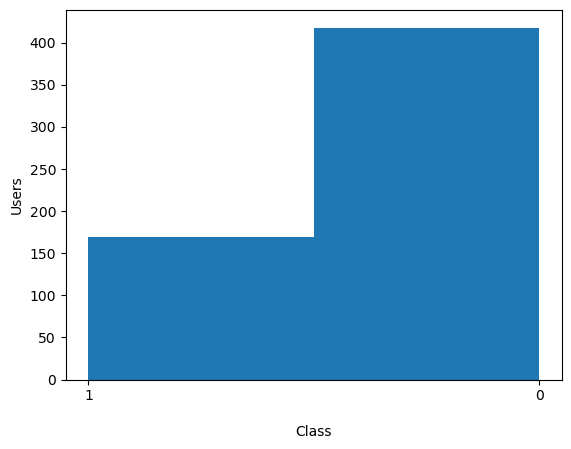

In [27]:
val_txt, val_y = get_texts_from_file("./mex20_val.txt", "./mex20_val_labels.txt")

print(Counter(val_y))
plt.hist(val_y, bins=len(set(val_y)))

plt.ylabel("Users");
plt.xlabel("Class");
plt.show()

In [28]:
BOW_val = build_bow_tr(val_txt, V, dict_indices)

In [29]:
BOW_val.shape

(587, 5000)

## Clasificación

In [30]:
# Parte 1 de Clasificación

tr_y = list(map(int, tr_y)) 
val_y = list(map(int, val_y)) 

from sklearn import svm
from sklearn.model_selection import GridSearchCV # Para varios experimentos y probar parametros
from sklearn import metrics
from sklearn.metrics import precision_recall_fscore_support

svm = svm.LinearSVC(class_weight='balanced')

In [31]:
# Parte 2
parameters = {'C': [.5, .12, .25, .5, 1, 2, 4]}
# varios experimentos a probar un parametro 
grid = GridSearchCV(estimator=svm, param_grid=parameters, n_jobs=4, scoring="f1_macro", cv=5 )

grid.fit(BOW_tr, tr_y) # llevar a cabo entrenamiento sobre la bolsa de palabras de TRAIN

y_pred = grid.predict(BOW_val)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the n

In [32]:
print(metrics.classification_report(val_y, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.88      0.88       418
           1       0.71      0.73      0.72       169

    accuracy                           0.83       587
   macro avg       0.80      0.80      0.80       587
weighted avg       0.84      0.83      0.84       587



In [33]:
incorrect = [] 
for e in zip(val_y, y_pred, range(len(val_y))):
  if e[0] != e[1]: # Si la etiqueta anotada no coincide con la predicción
    incorrect += [e[2]] # dime el número de instancia dónde se equivoco

In [34]:
for e in incorrect: 
  case = e
  if "madre" in val_txt[case].strip():
      print("Texto: ", val_txt[case].strip())
      print("Truth: ", val_y[case])
      print("Pred: ", y_pred[case])

Texto:  Al perro que se te acerque le parto su madre a si de facil
Truth:  1
Pred:  0
Texto:  @USUARIO Ya m tienen hasta la madre esos maes
Truth:  0
Pred:  1
Texto:  Amigos, Vero tiene toda la razón por eso no hay que ir a esa madre, mejor todos a Costeño a empedar.
Truth:  0
Pred:  1
Texto:  @USUARIO PA tener 80 estas a toda madre!
Truth:  0
Pred:  1
Texto:  Por está madre me agarré a vergazos con el de la combi y no le pagué, el puto decía que ya no valen.
Truth:  1
Pred:  0
Texto:  Ya van a ser las putas 8 y la pasarela no tiene para cuando empezar perra madre
Truth:  0
Pred:  1
Texto:  Políticos pseudoaficiomados que sólo en finales hablan de beisbol pueden ir mucho a chingar a su madre. Y peor cuando opinan.
Truth:  1
Pred:  0
Texto:  @USUARIO @USUARIO Hija de tu madre 😂😂😂😂🖕🏼🖕🏼🤚🏻
Truth:  0
Pred:  1
Texto:  La anciana madre de Freddie Mercury desmitifica a su hijo
Truth:  0
Pred:  1
Texto:  @USUARIO No tienen abuela madre vergüenza....
Truth:  1
Pred:  0


In [35]:
from sklearn.feature_selection import SelectKBest, chi2

In [86]:
feats = SelectKBest(chi2, k=500)
feats.fit(BOW_tr, tr_y)

SelectKBest(k=500, score_func=<function chi2 at 0x31fa1d1c0>)

In [87]:
best = feats.get_support(indices=True)

In [88]:
best

array([   1,    4,    5,    8,    9,   10,   12,   15,   16,   17,   22,
         24,   27,   29,   31,   35,   36,   38,   39,   43,   46,   49,
         50,   51,   53,   56,   58,   59,   60,   62,   64,   65,   67,
         70,   76,   79,   80,   84,   86,   87,   88,   96,   97,   98,
         99,  101,  104,  105,  107,  110,  111,  112,  113,  117,  119,
        120,  122,  124,  126,  132,  134,  135,  137,  139,  153,  155,
        165,  167,  168,  172,  179,  187,  191,  193,  194,  198,  201,
        202,  203,  208,  219,  221,  222,  225,  233,  236,  240,  245,
        247,  248,  253,  254,  256,  258,  261,  265,  269,  276,  277,
        278,  279,  287,  290,  292,  293,  299,  302,  306,  315,  316,
        317,  320,  327,  329,  335,  344,  346,  353,  360,  362,  370,
        376,  379,  384,  386,  389,  392,  395,  401,  419,  421,  422,
        428,  436,  438,  440,  442,  443,  461,  463,  465,  468,  469,
        471,  473,  475,  480,  481,  482,  484,  4

In [89]:
dict_indices

{'que': 0,
 'de': 1,
 ',': 2,
 '.': 3,
 'la': 4,
 'a': 5,
 'y': 6,
 'no': 7,
 'me': 8,
 '!': 9,
 '@usuario': 10,
 'el': 11,
 'en': 12,
 'se': 13,
 'es': 14,
 'verga': 15,
 'madre': 16,
 'los': 17,
 'con': 18,
 'por': 19,
 '?': 20,
 'las': 21,
 'mi': 22,
 'un': 23,
 'te': 24,
 'ya': 25,
 'si': 26,
 'putos': 27,
 'lo': 28,
 '"': 29,
 'putas': 30,
 'una': 31,
 'para': 32,
 'como': 33,
 '...': 34,
 'pero': 35,
 'su': 36,
 '😂': 37,
 'tu': 38,
 'loca': 39,
 'le': 40,
 'más': 41,
 'gorda': 42,
 'yo': 43,
 'del': 44,
 'al': 45,
 'cuando': 46,
 'o': 47,
 'bien': 48,
 'son': 49,
 'estoy': 50,
 '¿': 51,
 'qué': 52,
 'porque': 53,
 'feas': 54,
 'ni': 55,
 'está': 56,
 'les': 57,
 'pinche': 58,
 'esta': 59,
 'puta': 60,
 'todos': 61,
 ':': 62,
 'ser': 63,
 'puto': 64,
 'sus': 65,
 'todo': 66,
 'soy': 67,
 'eso': 68,
 'tan': 69,
 'hdp': 70,
 'así': 71,
 'hasta': 72,
 'muy': 73,
 'hay': 74,
 '…': 75,
 'mis': 76,
 'este': 77,
 'mamar': 78,
 'quiero': 79,
 'q': 80,
 'nos': 81,
 'solo': 82,
 '¡': 83,
 '

In [90]:
!pip install wordcloud

In [91]:
from wordcloud import WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="black").generate_from_frequencies(fdist)

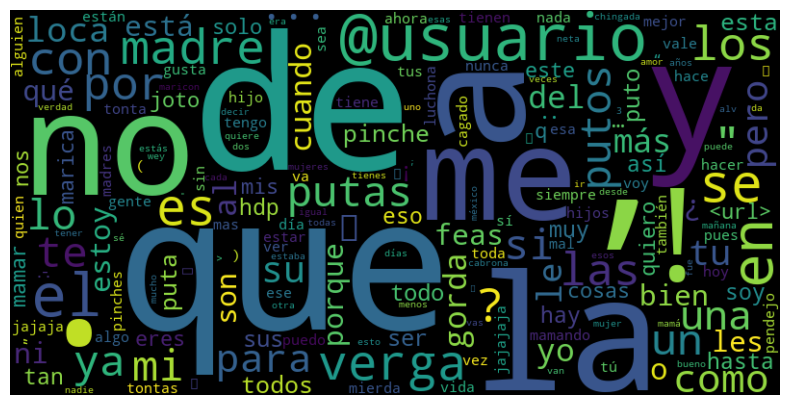

In [92]:
# imprimir nube
plt.figure(figsize = (10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [93]:
fdist

FreqDist({'que': 3111, 'de': 3094, ',': 3016, '.': 2604, 'la': 2269, 'a': 2205, 'y': 2098, 'no': 1819, 'me': 1475, '!': 1435, ...})

In [94]:
len(feats.scores_)

5000

In [95]:
chi2_scores = feats.scores_

In [96]:
best_scores = feats.scores_[best]

In [97]:
len(best_scores)

500

In [98]:
dict_indices_invertido = {}
for w in dict_indices:
    dict_indices_invertido[dict_indices[w]] = w

In [99]:
best_dict = {str(dict_indices_invertido[idx]) : chi2_scores [idx] for idx in best}

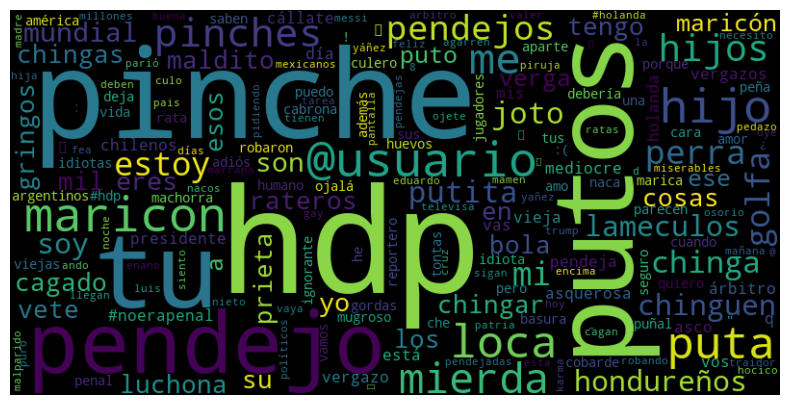

In [100]:
wordcloud = WordCloud(width=800, height=400, background_color="black").generate_from_frequencies(best_dict)

plt.figure(figsize = (10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()